In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install seaborn
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# Load Dataset
dataset = load_breast_cancer()

# Features
X = pd.DataFrame(
    dataset.data,
    columns=dataset.feature_names
)

# Target
y = pd.Series(
    (dataset.target == 0).astype(int),
    name="Target"
)

print("Dataset Loaded Successfully!")

print("Total Rows:", X.shape[0])
print("Total Features:", X.shape[1])

print("\nFirst Five Rows:")
display(X.head())

print("\nTarget Distribution:")
print(y.value_counts())

print("\nTarget Classes:")
print(y.value_counts().rename(index={
    0: "Benign",
    1: "Malignant"
}))

Dataset Loaded Successfully!
Total Rows: 569
Total Features: 30

First Five Rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target Distribution:
Target
0    357
1    212
Name: count, dtype: int64

Target Classes:
Target
Benign       357
Malignant    212
Name: count, dtype: int64


In [6]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data Preprocessing Completed!")

print("Training Samples:", X_train_scaled.shape[0])
print("Testing Samples:", X_test_scaled.shape[0])
print("Number of Features:", X_train_scaled.shape[1])

Data Preprocessing Completed!
Training Samples: 455
Testing Samples: 114
Number of Features: 30


In [7]:
# Create Single Layer Perceptron

slp_model = Perceptron(
    penalty="l2",
    alpha=0.0001,
    fit_intercept=True,
    max_iter=2000,
    tol=0.0001,
    shuffle=True,
    eta0=0.01,
    random_state=42,
    early_stopping=False,
    n_iter_no_change=10,
    warm_start=False,
    class_weight="balanced"
)

# Train model
slp_model.fit(X_train_scaled, y_train)

# Predictions
slp_predictions = slp_model.predict(X_test_scaled)

print("Single Layer Perceptron Trained Successfully!")

print("Number of Iterations:", slp_model.n_iter_)
print("Number of Features:", slp_model.n_features_in_)
print("Model Coefficients:", slp_model.coef_.shape)
print("Bias:", slp_model.intercept_)

Single Layer Perceptron Trained Successfully!
Number of Iterations: 20
Number of Features: 30
Model Coefficients: (1, 30)
Bias: [0.0676161]


MULTILAYER PERCEPTRON

In [8]:
# Create Multilayer Perceptron

mlp_model = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    batch_size=32,
    learning_rate="adaptive",
    learning_rate_init=0.001,
    max_iter=500,
    shuffle=True,
    random_state=42,
    tol=0.0001,
    verbose=False,
    warm_start=False,
    momentum=0.9,
    nesterovs_momentum=True,
    early_stopping=True,
    validation_fraction=0.15,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-8,
    n_iter_no_change=20,
    max_fun=15000
)

# Train MLP model
mlp_model.fit(X_train_scaled, y_train)

# Predictions
mlp_predictions = mlp_model.predict(X_test_scaled)

print("Multilayer Perceptron Trained Successfully!")

print("Number of Iterations:", mlp_model.n_iter_)
print("Number of Features:", mlp_model.n_features_in_)
print("Hidden Layers:", mlp_model.hidden_layer_sizes)
print("Training Loss:", mlp_model.loss_)

Multilayer Perceptron Trained Successfully!
Number of Iterations: 26
Number of Features: 30
Hidden Layers: (128, 64, 32)
Training Loss: 0.0053389289399474425


In [9]:
# Function for model evaluation

def evaluate_model(y_true, y_pred, model_name):

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    print("\n", "=" * 45)
    print(model_name)
    print("=" * 45)

    print("Accuracy :", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=["Benign", "Malignant"]
    ))

    return accuracy, precision, recall, f1


# Evaluate SLP
slp_results = evaluate_model(
    y_test,
    slp_predictions,
    "Single Layer Perceptron"
)

# Evaluate MLP
mlp_results = evaluate_model(
    y_test,
    mlp_predictions,
    "Multilayer Perceptron"
)


Single Layer Perceptron
Accuracy : 96.49 %
Precision: 0.9524
Recall   : 0.9524
F1 Score : 0.9524

Classification Report:
              precision    recall  f1-score   support

      Benign       0.97      0.97      0.97        72
   Malignant       0.95      0.95      0.95        42

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114


Multilayer Perceptron
Accuracy : 96.49 %
Precision: 0.9318
Recall   : 0.9762
F1 Score : 0.9535

Classification Report:
              precision    recall  f1-score   support

      Benign       0.99      0.96      0.97        72
   Malignant       0.93      0.98      0.95        42

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



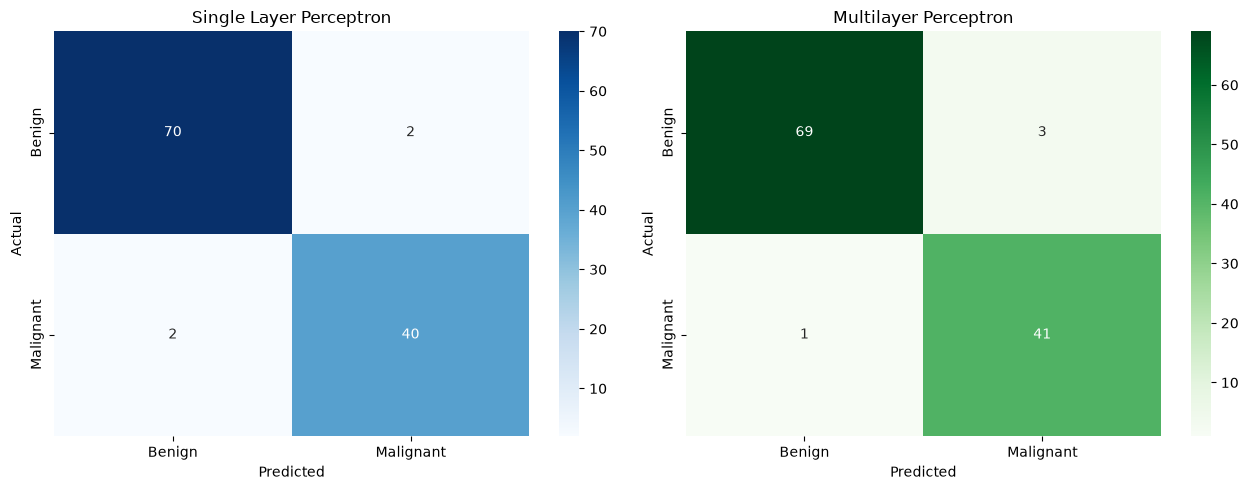

In [10]:
# Create confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# SLP Confusion Matrix
sns.heatmap(
    confusion_matrix(y_test, slp_predictions),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"],
    ax=axes[0]
)

axes[0].set_title("Single Layer Perceptron")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# MLP Confusion Matrix
sns.heatmap(
    confusion_matrix(y_test, mlp_predictions),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"],
    ax=axes[1]
)

axes[1].set_title("Multilayer Perceptron")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

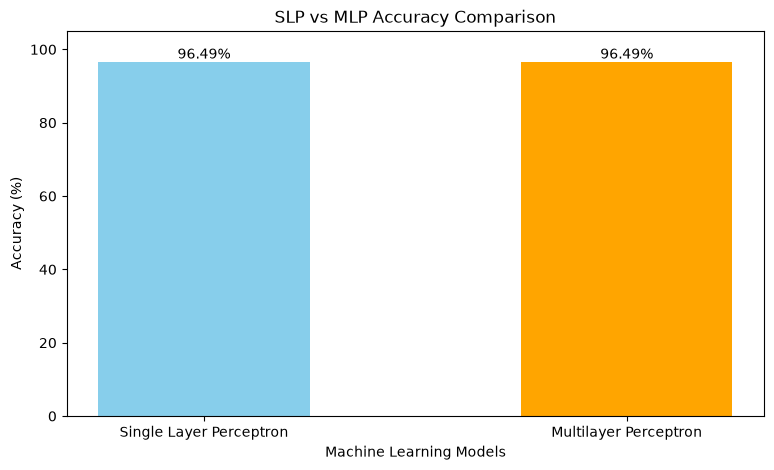

In [11]:
# Accuracy comparison

model_names = [
    "Single Layer Perceptron",
    "Multilayer Perceptron"
]

accuracies = [
    slp_results[0] * 100,
    mlp_results[0] * 100
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    model_names,
    accuracies,
    width=0.5,
    color=["skyblue", "orange"]
)

plt.title("SLP vs MLP Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 105)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 1,
        f"{height:.2f}%",
        ha="center"
    )

plt.show()

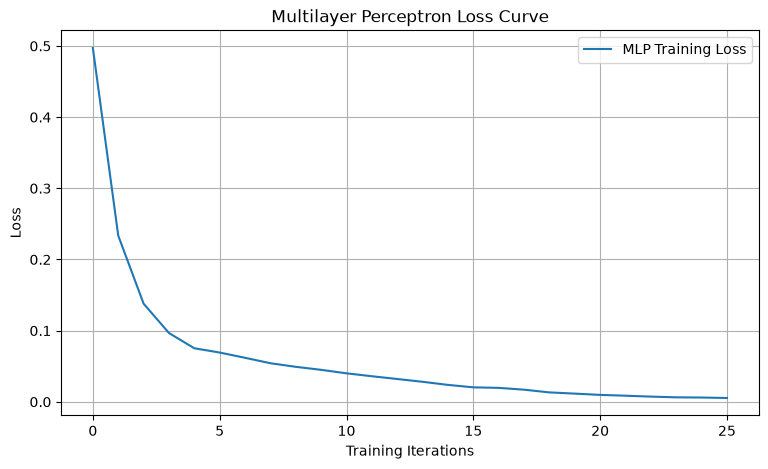

In [12]:
plt.figure(figsize=(9, 5))

plt.plot(
    mlp_model.loss_curve_,
    label="MLP Training Loss"
)

plt.title("Multilayer Perceptron Loss Curve")
plt.xlabel("Training Iterations")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

In [14]:
# Create Comparison DataFrame

comparison = pd.DataFrame({
    "Evaluation Metrics": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],

    "Single Layer Perceptron": [
        slp_results[0],
        slp_results[1],
        slp_results[2],
        slp_results[3]
    ],

    "Multilayer Perceptron": [
        mlp_results[0],
        mlp_results[1],
        mlp_results[2],
        mlp_results[3]
    ]
})

# Display comparison table

print("\nSLP vs MLP Performance Comparison")
print("=" * 60)

display(comparison.round(4))

print("\nComparison Completed Successfully!")


SLP vs MLP Performance Comparison


,Evaluation Metrics,Single Layer Perceptron,Multilayer Perceptron
0,Accuracy,0.9649,0.9649
1,Precision,0.9524,0.9318
2,Recall,0.9524,0.9762
3,F1 Score,0.9524,0.9535



Comparison Completed Successfully!


In [15]:
# Select a sample from dataset

sample_input = X.iloc[[0]]

# Scale the sample
sample_scaled = scaler.transform(sample_input)

# Predict using SLP
slp_result = slp_model.predict(sample_scaled)[0]

# Predict using MLP
mlp_result = mlp_model.predict(sample_scaled)[0]

# Class labels
labels = {
    0: "Benign",
    1: "Malignant"
}

print("SLP Prediction:", labels[slp_result])
print("MLP Prediction:", labels[mlp_result])

print("\nActual Result:", labels[y.iloc[0]])

SLP Prediction: Malignant
MLP Prediction: Malignant

Actual Result: Malignant
